# Indian Used Car Price Prediction & Market Analysis

## 1. Project Overview

This project focuses on analysing the Indian used car market
and developing machine learning models to predict used car prices.

## 2. Objectives

- Understand the dataset and its features.
- Perform Exploratory Data Analysis (EDA).
- Identify factors affecting used car prices.
- Develop and compare regression models.
- Evaluate model performance.

## 3. Dataset

Source: Kaggle - Used Cars Price Prediction

In [134]:
# Data manipulation

import numpy as np
import pandas as pd

# Data visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Display settings

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [135]:
# Load training dataset
df = pd.read_csv('../data/raw/train-data.csv')

# Load testing dataset
test_df = pd.read_csv('../data/raw/test-data.csv')

print("Datasets loaded successfully!")


Datasets loaded successfully!


In [136]:
print("Training Dataset:", df.shape)
print("Testing Dataset:", test_df.shape)

Training Dataset: (6019, 14)
Testing Dataset: (1234, 13)


In [137]:
df.head()

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74


In [138]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         6019 non-null   int64  
 1   Name               6019 non-null   str    
 2   Location           6019 non-null   str    
 3   Year               6019 non-null   int64  
 4   Kilometers_Driven  6019 non-null   int64  
 5   Fuel_Type          6019 non-null   str    
 6   Transmission       6019 non-null   str    
 7   Owner_Type         6019 non-null   str    
 8   Mileage            6017 non-null   str    
 9   Engine             5983 non-null   str    
 10  Power              5983 non-null   str    
 11  Seats              5977 non-null   float64
 12  New_Price          824 non-null    str    
 13  Price              6019 non-null   float64
dtypes: float64(2), int64(3), str(9)
memory usage: 658.5 KB


In [139]:
df.describe().T



,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,6019.0,3009.000000,1737.679967,0.00,1504.5,3009.00,4513.50,6018.0
Year,6019.0,2013.358199,3.269742,1998.00,2011.0,2014.00,2016.00,2019.0
Kilometers_Driven,6019.0,58738.380296,91268.843206,171.00,34000.0,53000.00,73000.00,6500000.0
Seats,5977.0,5.278735,0.808840,0.00,5.0,5.00,5.00,10.0
Price,6019.0,9.479468,11.187917,0.44,3.5,5.64,9.95,160.0


In [140]:
df.describe(include='object').T

C:\Users\sreer\AppData\Local\Temp\ipykernel_28104\1760094569.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object').T


,count,unique,top,freq
Name,6019,1876,Mahindra XUV500 W8 2WD,49
Location,6019,11,Mumbai,790
Fuel_Type,6019,5,Diesel,3205
Transmission,6019,2,Manual,4299
Owner_Type,6019,4,First,4929
Mileage,6017,442,18.9 kmpl,172
Engine,5983,146,1197 CC,606
Power,5983,372,74 bhp,235
New_Price,824,540,95.13 Lakh,6


In [141]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [142]:
df.isnull().sum()

Unnamed: 0              0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 2
Engine                 36
Power                  36
Seats                  42
New_Price            5195
Price                   0
dtype: int64

In [143]:
df['Unnamed: 0'].head(10)

0    0
1    1
2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
Name: Unnamed: 0, dtype: int64

In [144]:
# seats min 0 - invalid

df[df['Seats']<=0]

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
3999,3999,Audi A4 3.2 FSI Tiptronic Quattro,Hyderabad,2012,125000,Petrol,Automatic,First,10.5 kmpl,3197 CC,null bhp,0.0,NaN,18.0


In [145]:
# Identify vehicles with unusually high kilometers driven

df.nlargest(10, 'Kilometers_Driven')[
    ['Name', 'Year', 'Kilometers_Driven', 'Price']
]

,Name,Year,Kilometers_Driven,Price
2328,BMW X5 xDrive 30d M Sport,2017,6500000,65.00
340,Skoda Octavia Ambition Plus 2.0 TDI AT,2013,775000,7.50
1860,Volkswagen Vento Diesel Highline,2013,720000,5.90
358,Hyundai i10 Magna 1.2,2009,620000,2.70
2823,Volkswagen Jetta 2013-2015 2.0L TDI Highline AT,2015,480000,13.00
3092,Honda City i VTEC SV,2015,480000,5.00
4491,Hyundai i20 Magna Optional 1.2,2013,445000,4.45
3649,Tata Indigo LS,2008,300000,1.00
1528,Toyota Innova 2.5 G (Diesel) 8 Seater BS IV,2005,299322,4.00
1975,Skoda Superb 1.8 TSI MT,2012,282000,3.30


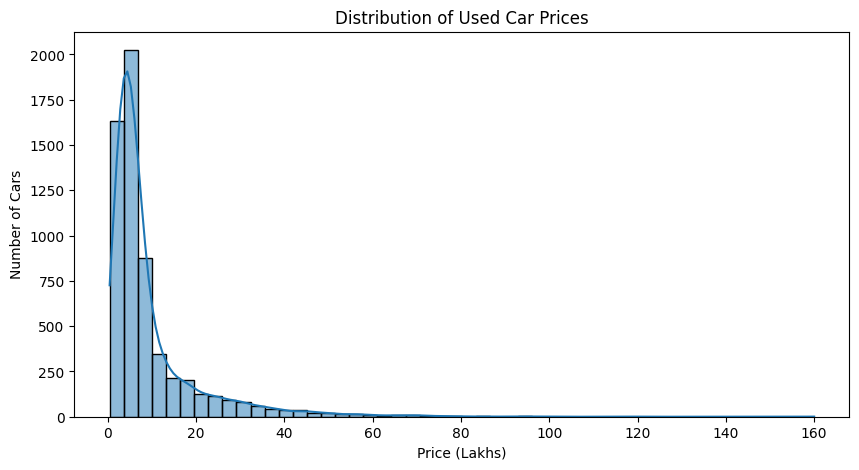

In [146]:
# mean > median  -might be right skewed

plt.figure(figsize=(10, 5))

sns.histplot(df['Price'], bins=50, kde=True)

plt.title('Distribution of Used Car Prices')
plt.xlabel('Price (Lakhs)')
plt.ylabel('Number of Cars')

plt.show()

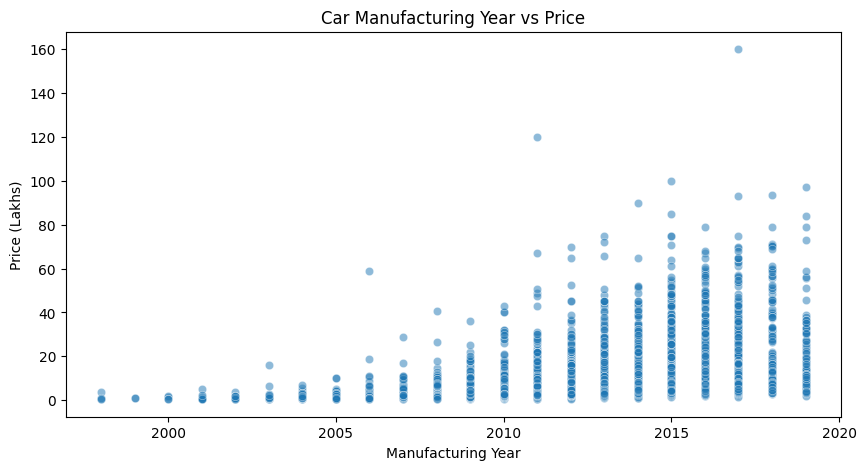

In [147]:
# Do newer cars generally have higher resale prices than older cars?

plt.figure(figsize=(10, 5))

sns.scatterplot(data=df, x='Year', y='Price', alpha=0.5)

plt.title('Car Manufacturing Year vs Price')
plt.xlabel('Manufacturing Year')
plt.ylabel('Price (Lakhs)')

plt.show()

### Year and Price - Observations
The scatter plot shows that newer cars, especially those manufactured after 2015, generally have higher resale prices. Older cars, particularly those manufactured around 2000, tend to have lower prices.

This indicates a relationship between the manufacturing year and resale price. The value of a car generally decreases as it gets older due to depreciation.

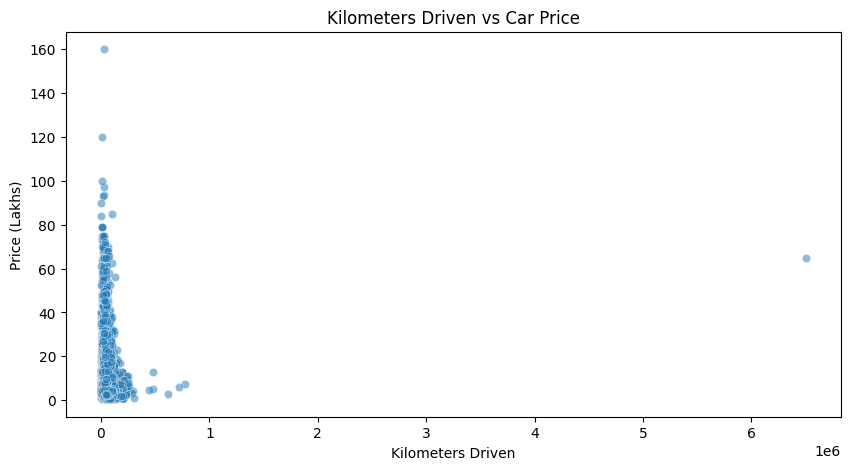

In [148]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='Kilometers_Driven', y='Price', alpha=0.5)

plt.title('Kilometers Driven vs Car Price')
plt.xlabel('Kilometers Driven')
plt.ylabel('Price (Lakhs)')
plt.show()

### Kilometers Driven and Price - Observations
Most cars in the dataset have been driven between 0 and 100,000 kilometres. The majority of car prices are concentrated below 80 lakhs.

One observation shows an unusually high distance of 6,500,000 kilometres. This could be a potential outlier or data-entry error and requires further investigation.

In [149]:
df[df['Kilometers_Driven'] > 1000000]

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
2328,2328,BMW X5 xDrive 30d M Sport,Chennai,2017,6500000,Diesel,Automatic,First,15.97 kmpl,2993 CC,258 bhp,5.0,NaN,65.0


### Outlier Investigation

A BMW X5 (2017 model) was found with 6,500,000 kilometres driven and a resale price of 65 lakhs.

This mileage value is unusually high compared to other records and may indicate a data-entry error. The original value is retained until further verification.


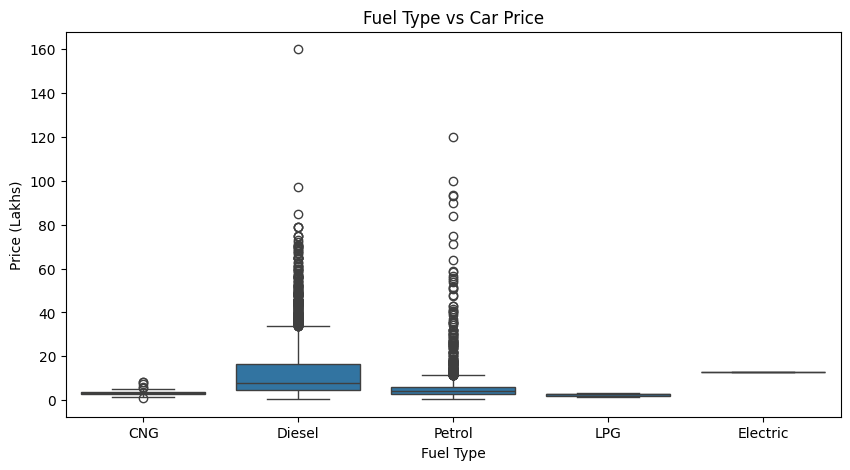

In [150]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Fuel_Type', y='Price')

plt.title('Fuel Type vs Car Price')
plt.xlabel('Fuel Type')
plt.ylabel('Price (Lakhs)')
plt.show()

### Fuel Type and Price - Observations

The box plot shows differences in price distribution across fuel types.

- Diesel cars generally have higher prices, with an extreme outlier around 160 lakhs.
- Most petrol cars are priced below 10 lakhs, although a few expensive vehicles are present.
- CNG and LPG cars generally have lower prices.
- Electric cars appear to be concentrated around the middle price range of 25–30 lakhs.

This suggests that fuel type may be an important feature influencing used car prices.


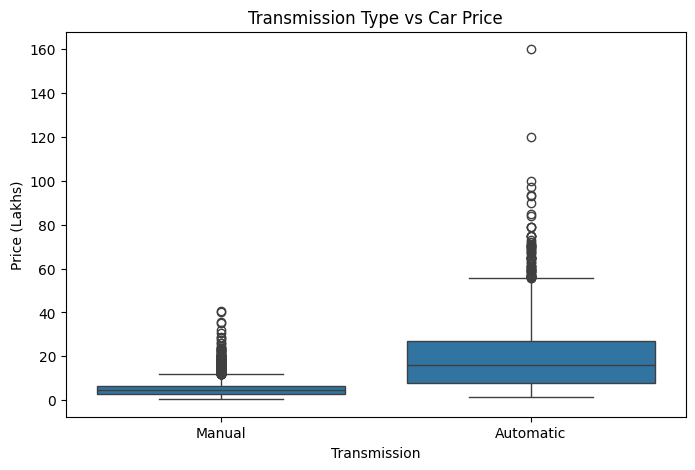

In [151]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Transmission', y='Price')

plt.title('Transmission Type vs Car Price')
plt.xlabel('Transmission')
plt.ylabel('Price (Lakhs)')

plt.show()

### Transmission and Price - Observations

The box plot shows that automatic cars generally have higher prices than manual cars.

- Automatic cars have a median price of approximately 20–25 lakhs and a wider price distribution.
- Manual cars have a median price of approximately 5–10 lakhs with a comparatively narrower distribution.
- Automatic cars contain high-value outliers between 100 and 160 lakhs.
- Manual cars also have some outliers around 50 lakhs.

This indicates that transmission type may be an important feature associated with used car prices.

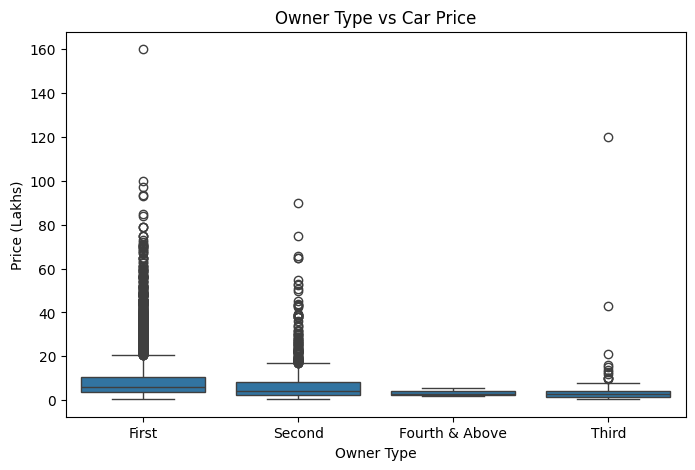

In [152]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Owner_Type', y='Price')

plt.title('Owner Type vs Car Price')
plt.xlabel('Owner Type')
plt.ylabel('Price (Lakhs)')

plt.show()

### Owner Type and Price - Observations

The box plot shows a relationship between ownership history and used car prices.

- First-owner cars generally have higher prices.
- Fourth-owner and above cars show comparatively lower prices.
- First-owner cars contain an extreme outlier around 160 lakhs.
- Third-owner cars also contain a high-value outlier around 120 lakhs.

This suggests that ownership history may influence the resale price of a used car.

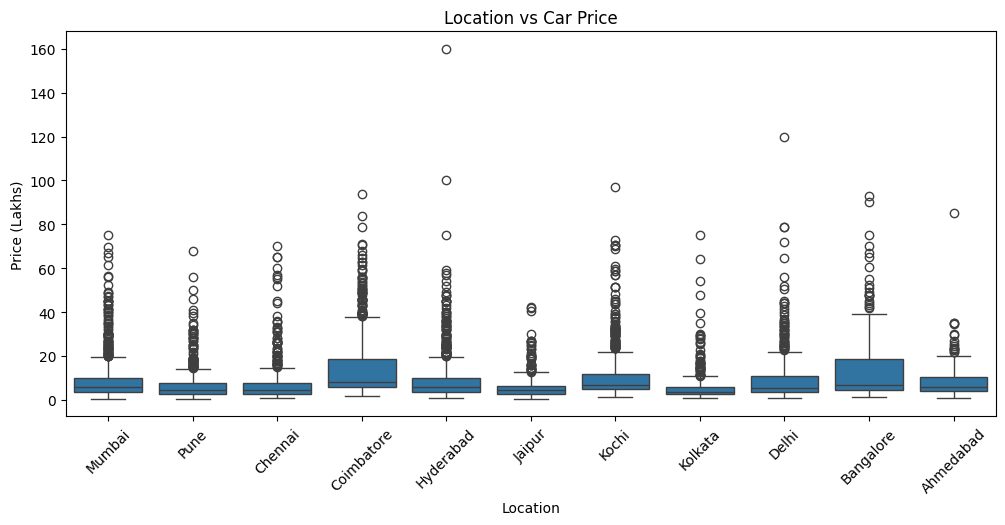

In [153]:
plt.figure(figsize=(12, 5))

sns.boxplot(data=df, x='Location', y='Price')

plt.title('Location vs Car Price')
plt.xlabel('Location')
plt.ylabel('Price (Lakhs)')
plt.xticks(rotation=45)

plt.show()

### Location and Price - Observations

The box plot reveals differences in used car price distributions across cities.

* **Highest Median Price:** Coimbatore has the highest median car price, followed closely by Bangalore.
* **Lowest Median Price:** Kolkata has the lowest median car price among the listed locations.
* **Highest Outlier:** Hyderabad contains an extreme price outlier of approximately ₹160 lakhs.
* **Price Variation:** Coimbatore and Bangalore show wider price distributions, indicating greater variation in car prices. Jaipur and Kolkata have comparatively narrower distributions.

These observations suggest that location may be associated with differences in used car prices. However, other factors such as car brand, manufacturing year and model may also contribute to these differences.


In [154]:

# Extract car brands from car names

df['Brand'] = df['Name'].apply(
    lambda name: 'Land Rover' if name.startswith('Land Rover')
    else name.split()[0]
)

# Standardize brand names
df['Brand'] = df['Brand'].replace({
    'ISUZU': 'Isuzu',
    'Bmw': 'BMW'
})

# Display the top 15 brands
df['Brand'].value_counts().head(15)

Brand
Maruti           1211
Hyundai          1107
Honda             608
Toyota            411
Mercedes-Benz     318
Volkswagen        315
Ford              300
Mahindra          272
BMW               267
Audi              236
Tata              186
Skoda             173
Renault           145
Chevrolet         121
Nissan             91
Name: count, dtype: int64

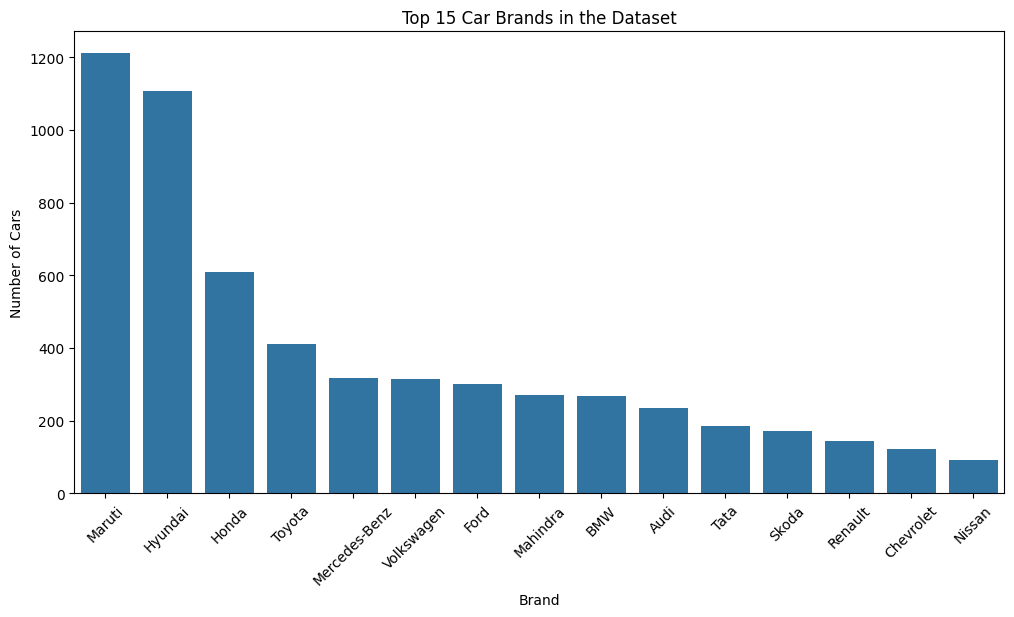

In [155]:
plt.figure(figsize=(12, 6))

brand_counts = df['Brand'].value_counts().head(15)

sns.barplot(x=brand_counts.index, y=brand_counts.values)

plt.title('Top 15 Car Brands in the Dataset')
plt.xlabel('Brand')
plt.ylabel('Number of Cars')
plt.xticks(rotation=45)

plt.show()

In [156]:
brand_prices = df.groupby('Brand')['Price'].median().sort_values(ascending=False)

brand_prices.head(15)

Brand
Lamborghini      120.000
Bentley           59.000
Porsche           47.020
Land Rover        35.000
Jaguar            31.900
Mini              24.285
Mercedes-Benz     24.000
Audi              23.500
BMW               21.000
Jeep              18.500
Volvo             18.250
Isuzu             16.090
Toyota            10.750
Mitsubishi         9.950
Force              8.000
Name: Price, dtype: float64

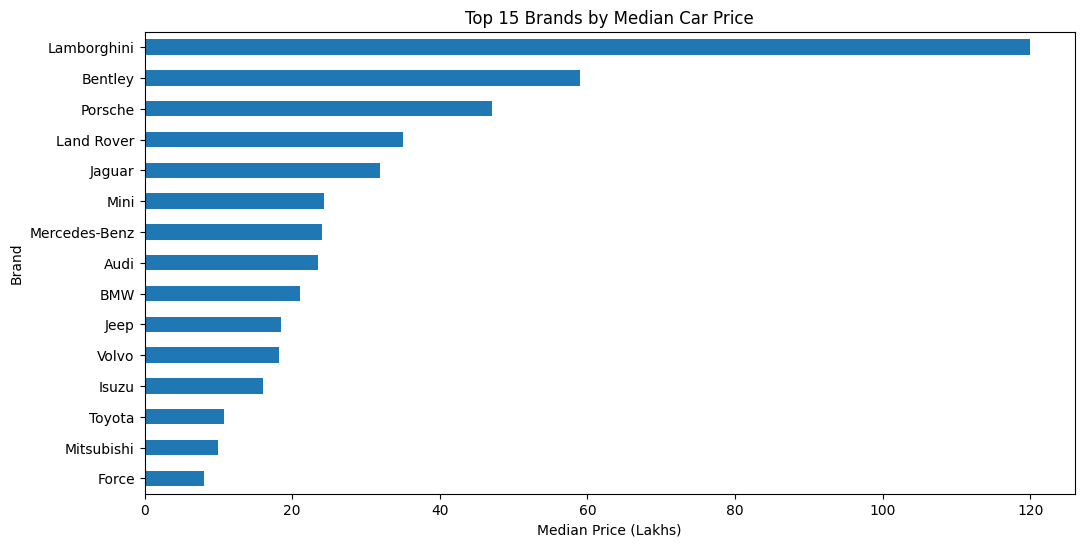

In [157]:
plt.figure(figsize=(12, 6))

brand_prices.head(15).sort_values().plot(kind='barh')

plt.title('Top 15 Brands by Median Car Price')
plt.xlabel('Median Price (Lakhs)')
plt.ylabel('Brand')

plt.show()

The brand-wise median price analysis reveals significant differences in resale prices across car manufacturers.

Lamborghini has the highest median price at ₹120 lakhs, followed by Bentley and Porsche.
Luxury brands such as Jaguar, Mercedes-Benz, Audi and BMW also show relatively high median prices.
Mass-market brands such as Toyota generally have lower median prices compared to luxury brands.

This indicates that car brand is an important factor associated with used car prices. However, the number of available listings for each brand should also be considered while interpreting these results.

In [158]:
brand_summary = (
    df.groupby('Brand')['Price']
    .agg(['median', 'count'])
    .sort_values('median', ascending=False)
)

brand_summary.head(15)

,median,count
Brand,,
Lamborghini,120.000,1
Bentley,59.000,1
Porsche,47.020,18
Land Rover,35.000,60
Jaguar,31.900,40
Mini,24.285,26
Mercedes-Benz,24.000,318
Audi,23.500,236
BMW,21.000,267


### Brand-wise Price Analysis

- Luxury brands such as Lamborghini, Bentley and Porsche show higher median prices.
- However, Lamborghini and Bentley have only one record each, so their median prices may not represent the overall market.
- Mercedes-Benz, Audi and BMW have relatively high median prices with larger sample sizes.
- Toyota has the highest number of listings among the top 15 brands.


### Popular Car Models Analysis

This section identifies the most frequently listed car models in the dataset and compares their median resale prices.

In [159]:
model_counts = df['Name'].value_counts().head(15)

model_counts

Name
Mahindra XUV500 W8 2WD        49
Maruti Swift VDI              45
Honda City 1.5 S MT           34
Maruti Swift Dzire VDI        34
Maruti Swift VDI BSIV         31
Maruti Ritz VDi               30
Hyundai i10 Sportz            30
Toyota Fortuner 3.0 Diesel    29
Honda Amaze S i-Dtech         27
Hyundai Grand i10 Sportz      27
Maruti Ertiga VDI             25
Honda Brio S MT               25
Honda City 1.5 V MT           24
Hyundai Verna 1.6 SX          23
Maruti Wagon R VXI            23
Name: count, dtype: int64

In [160]:
top_models = model_counts.index

model_prices = (
    df[df['Name'].isin(top_models)]
    .groupby('Name')['Price']
    .median()
    .sort_values(ascending=False)
)

model_prices

Name
Toyota Fortuner 3.0 Diesel    11.500
Mahindra XUV500 W8 2WD         7.900
Maruti Ertiga VDI              6.910
Hyundai Verna 1.6 SX           5.500
Maruti Swift Dzire VDI         5.300
Maruti Swift VDI BSIV          5.000
Maruti Swift VDI               4.800
Hyundai Grand i10 Sportz       4.780
Honda Amaze S i-Dtech          4.410
Honda City 1.5 S MT            3.950
Honda City 1.5 V MT            3.775
Honda Brio S MT                3.550
Maruti Wagon R VXI             3.410
Maruti Ritz VDi                3.345
Hyundai i10 Sportz             3.120
Name: Price, dtype: float64

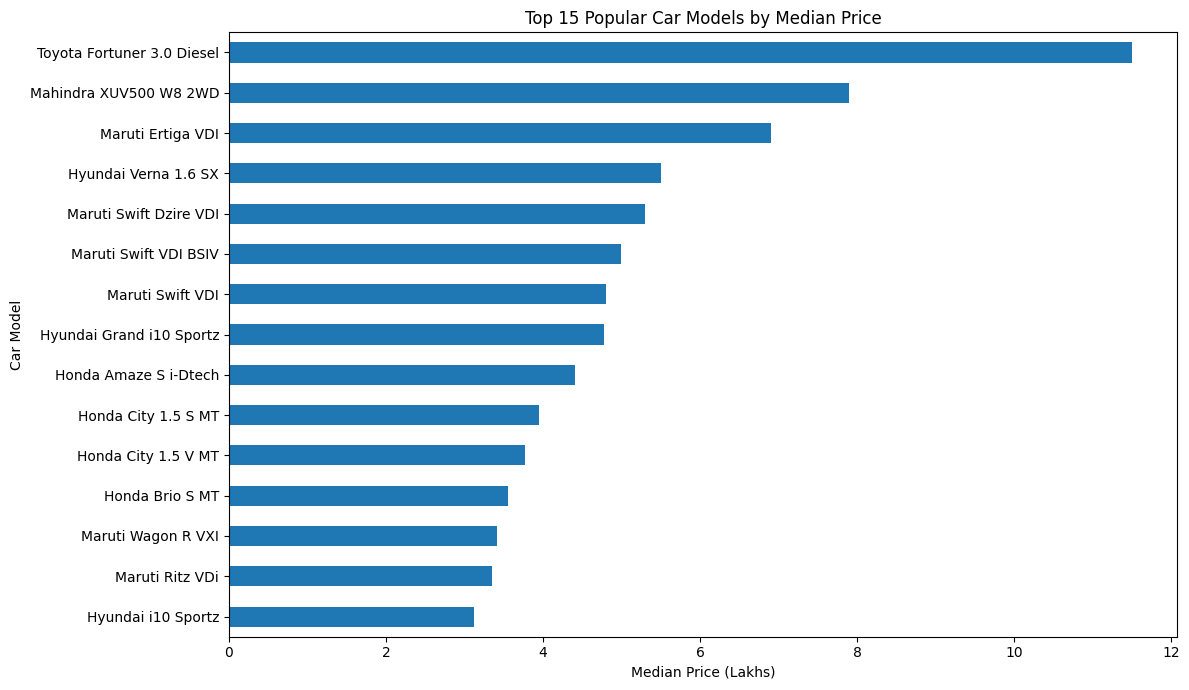

In [161]:
plt.figure(figsize=(12, 7))

model_prices.sort_values().plot(kind='barh')

plt.title('Top 15 Popular Car Models by Median Price')
plt.xlabel('Median Price (Lakhs)')
plt.ylabel('Car Model')

plt.tight_layout()
plt.show()


### Manufacturing Year Distribution



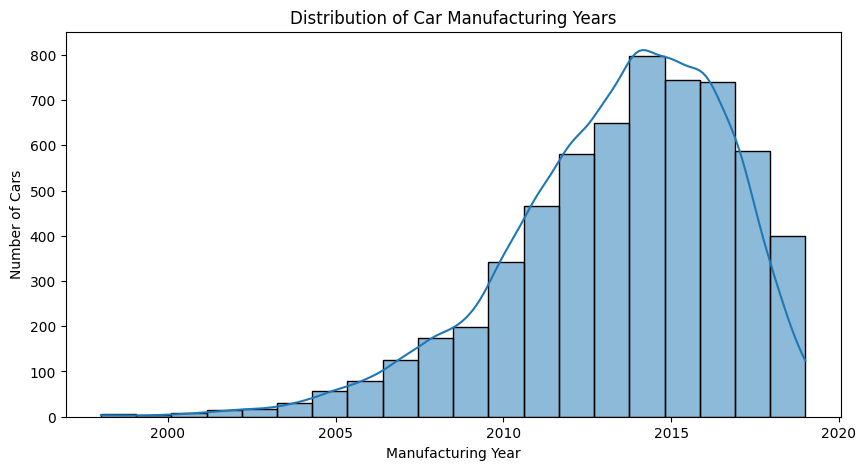

In [162]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='Year', bins=20, kde=True)

plt.title('Distribution of Car Manufacturing Years')
plt.xlabel('Manufacturing Year')
plt.ylabel('Number of Cars')

plt.show()

- Most cars in the dataset were manufactured between 2010 and 2017.
- The highest number of listings is observed around 2014.
- Very few cars belong to the period between 1998 and 2005.
- The number of listings increases significantly after 2010.
- A decline in listings is observed for recent manufacturing years (2018–2019).
- The dataset contains more relatively recent cars than older vehicles.

### Kilometers Driven Distribution


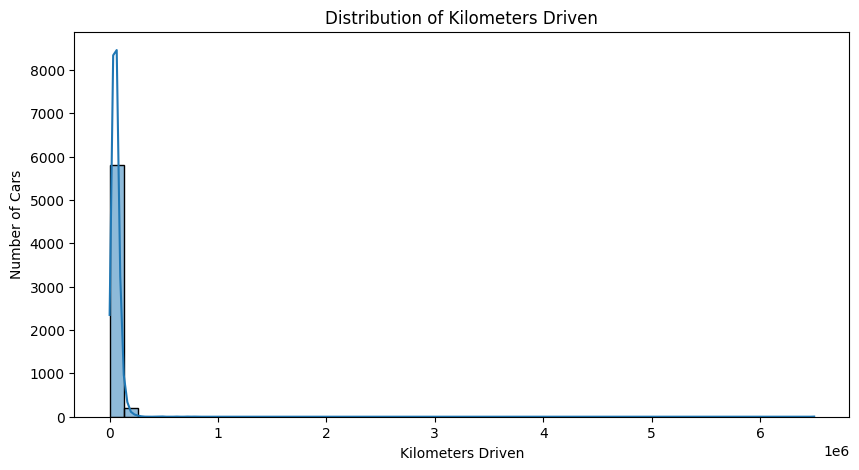

In [163]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='Kilometers_Driven', bins=50, kde=True)

plt.title('Distribution of Kilometers Driven')
plt.xlabel('Kilometers Driven')
plt.ylabel('Number of Cars')

plt.show()

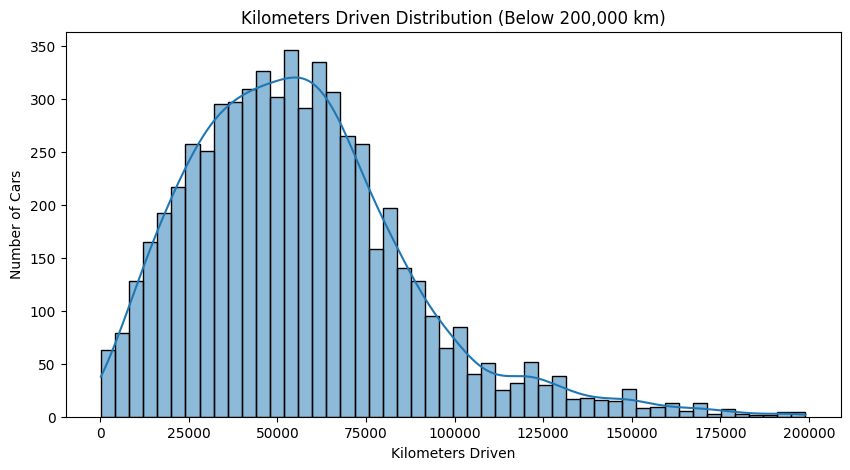

In [164]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df['Kilometers_Driven'] < 200000],
    x='Kilometers_Driven',
    bins=50,
    kde=True
)

plt.title('Kilometers Driven Distribution (Below 200,000 km)')
plt.xlabel('Kilometers Driven')
plt.ylabel('Number of Cars')

plt.show()

- Most cars have travelled between 40,000 and 70,000 kilometres.
- The highest frequency is observed around 55,000 kilometres, with nearly 350 cars.
- The number of cars decreases significantly beyond 100,000 kilometres.
- The distribution is right-skewed, with a long tail towards higher kilometre values.
- Extreme mileage values identified earlier require further investigation.

### Mileage Distribution


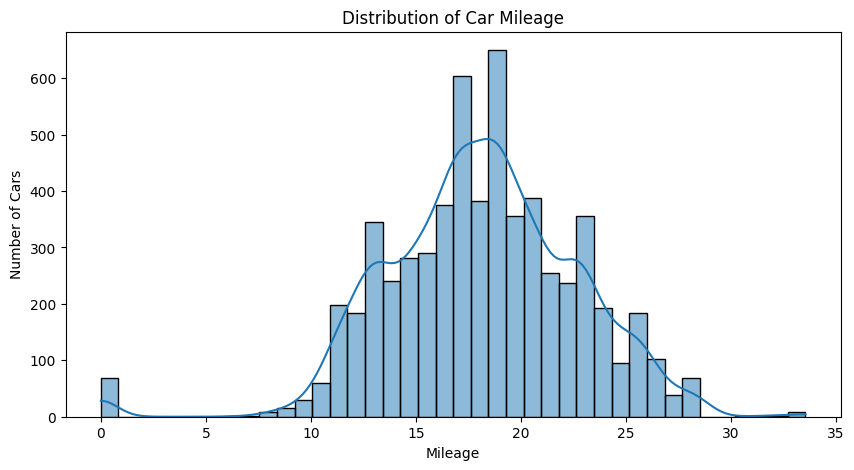

In [165]:
# Convert Mileage values into numeric format
mileage_numeric = pd.to_numeric(
    df['Mileage'].str.replace(' kmpl', '', regex=False)
                  .str.replace(' km/kg', '', regex=False),
    errors='coerce'
)

# Plot mileage distribution
plt.figure(figsize=(10, 5))

sns.histplot(mileage_numeric, bins=40, kde=True)

plt.title('Distribution of Car Mileage')
plt.xlabel('Mileage')
plt.ylabel('Number of Cars')

plt.show()

In [166]:
# Check zero mileage values

zero_mileage_count = (mileage_numeric == 0).sum()

print("Zero Mileage Values:", zero_mileage_count)

Zero Mileage Values: 68


- A total of 68 cars (approximately 1.13% of the dataset) have zero mileage values.
- These values are considered potentially invalid and may represent missing information.
- They will be investigated and handled during the data preprocessing stage.

- Most cars have a mileage between 12 and 24 kmpl.
- The highest frequency is observed around 18–19 kmpl, with nearly 650 cars.
- A small spike is observed at zero mileage, which may indicate missing or incorrect data.
- The distribution shows that most cars have moderate fuel efficiency.

### Engine Capacity Distribution



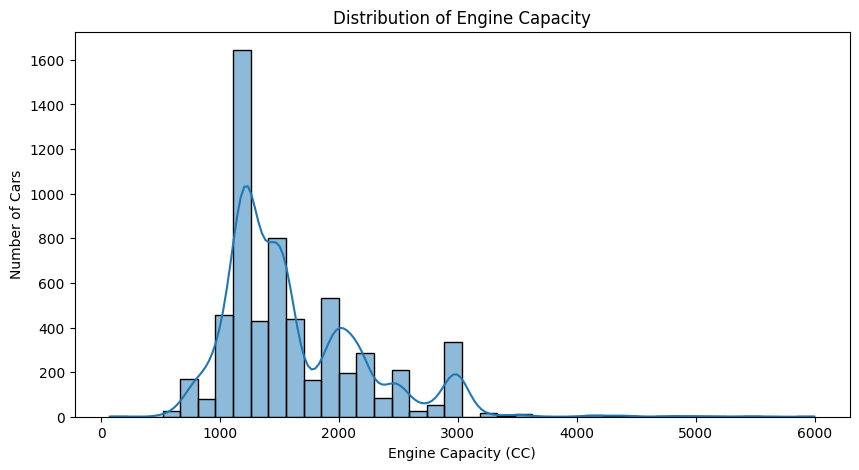

In [167]:
engine_numeric = pd.to_numeric(
    df['Engine'].str.replace(' CC', '', regex=False),
    errors='coerce'
)

plt.figure(figsize=(10, 5))

sns.histplot(engine_numeric, bins=40, kde=True)

plt.title('Distribution of Engine Capacity')
plt.xlabel('Engine Capacity (CC)')
plt.ylabel('Number of Cars')

plt.show()

- Most cars have an engine capacity between 1,000 CC and 1,500 CC.
- The highest frequency is observed around 1,200 CC, with more than 1,600 cars.
- Smaller peaks are observed around common engine capacities such as 1,500 CC, 2,000 CC and 3,000 CC.
- Very few cars have engine capacities above 3,500 CC.
- A small number of vehicles have engine capacities reaching approximately 6,000 CC.

### Power Distribution


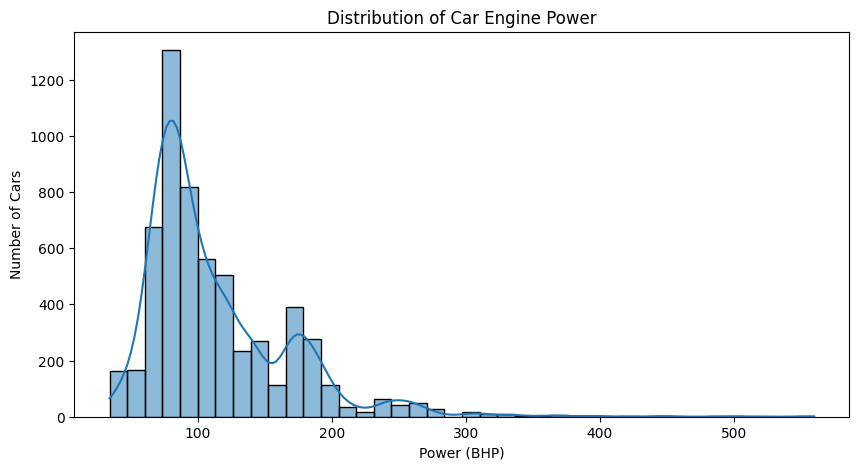

In [168]:
power_numeric = pd.to_numeric(
    df['Power'].str.replace(' bhp', '', regex=False),
    errors='coerce'
)

plt.figure(figsize=(10, 5))

sns.histplot(power_numeric, bins=40, kde=True)

plt.title('Distribution of Car Engine Power')
plt.xlabel('Power (BHP)')
plt.ylabel('Number of Cars')

plt.show()

In [169]:
power_numeric.isna().sum()


np.int64(143)

In [170]:
df.loc[power_numeric.isna(), 'Power'].value_counts(dropna=False)

Power
null bhp    107
NaN          36
Name: count, dtype: int64

- The Power column contains 36 actual missing values and 107 entries recorded as 'null bhp'.
- After numeric conversion, a total of 143 missing values were identified.
- These values represent approximately 2.38% of the dataset and will be handled during preprocessing.

- Most cars have engine power between 70 and 100 BHP.
- The highest frequency is observed just below 100 BHP, with more than 1,300 cars.
- A smaller peak is observed around 175 BHP.
- Very few cars have power above 300 BHP.
- A small number of high-performance vehicles have power exceeding 550 BHP.


### Seating Capacity Distribution




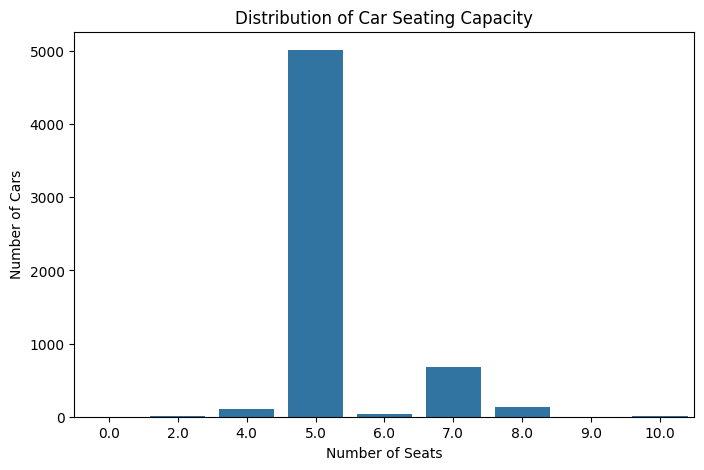

In [171]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Seats')

plt.title('Distribution of Car Seating Capacity')
plt.xlabel('Number of Seats')
plt.ylabel('Number of Cars')

plt.show()

In [172]:
print("Missing values:", df['Seats'].isnull().sum())
print("Zero seat values:", (df['Seats'] == 0).sum())

Missing values: 42
Zero seat values: 1


- The Seats column contains 42 missing values (approximately 0.70%).
- One record has a seating capacity of zero, which is an invalid value.
- These missing and invalid values will be investigated and handled during data preprocessing.

- The majority of cars in the dataset have a seating capacity of 5, with more than 5,000 records.
- Seven-seater cars form the second-largest group, with approximately 700 records.
- Other seating configurations, such as 2, 4, 6, 8 and 10 seats, are relatively rare.
- Five-seat vehicles dominate the dataset, indicating that standard passenger cars are the most commonly listed vehicles.

### New Price Column Analysis



In [173]:
print("Missing values:", df['New_Price'].isnull().sum())
print("Missing percentage:", df['New_Price'].isnull().mean() * 100)

Missing values: 5195
Missing percentage: 86.31001827546105


- The New_Price column contains 5,195 missing values (approximately 86.31%).
- Only 824 records have available New_Price information.
- Due to the extremely high percentage of missing values, this feature may not be reliable for model training.
- The column will be excluded from the initial model development.

### Correlation Analysis



In [174]:
# Create a temporary copy for correlation analysis
corr_df = df.copy()

# Reuse previously converted numerical columns
corr_df['Mileage'] = mileage_numeric
corr_df['Engine'] = engine_numeric
corr_df['Power'] = power_numeric

# Select numerical columns
numeric_df = corr_df.select_dtypes(include='number')

numeric_df.head()

,Unnamed: 0,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Price
0,0,2010,72000,26.60,998.0,58.16,5.0,1.75
1,1,2015,41000,19.67,1582.0,126.20,5.0,12.50
2,2,2011,46000,18.20,1199.0,88.70,5.0,4.50
3,3,2012,87000,20.77,1248.0,88.76,7.0,6.00
4,4,2013,40670,15.20,1968.0,140.80,5.0,17.74


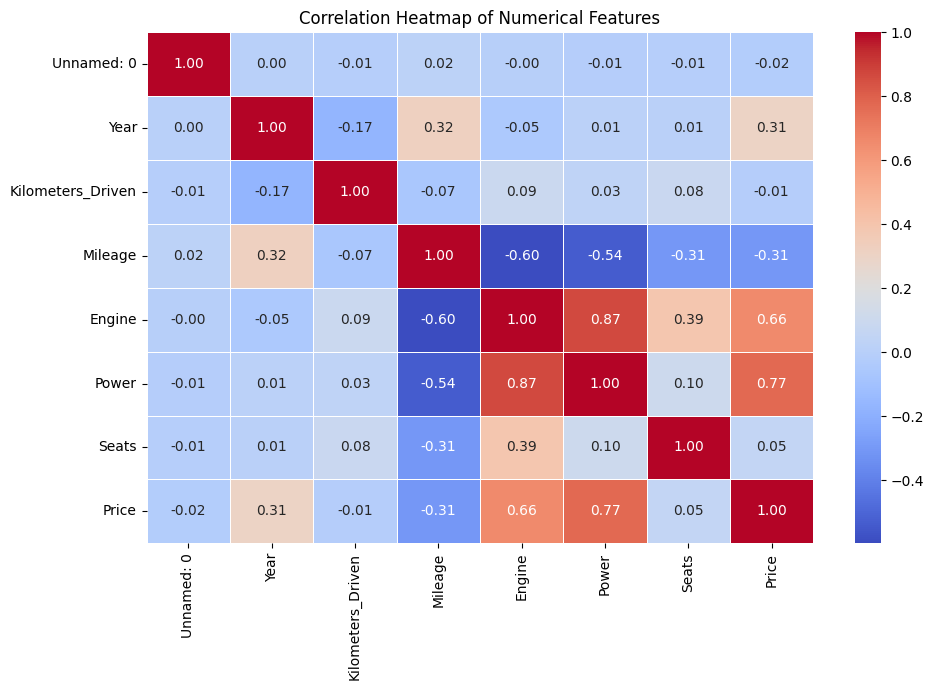

In [175]:
plt.figure(figsize=(10, 7))

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()


- Power shows the strongest positive correlation with Price (0.77), followed by Engine (0.66).
- Year has a moderate positive correlation with Price (0.31).
- Mileage shows a negative correlation with Price (-0.31).
- Seats (0.05) and Kilometers_Driven (-0.01) show very weak linear relationships with Price.
- Engine and Power have a strong positive correlation of 0.87.
- Engine and Mileage show a negative correlation of -0.60.
- These relationships provide useful insights into the numerical features that may influence car price prediction.
- Correlation indicates association and does not necessarily imply causation

# Exploratory Data Analysis - Summary

The dataset contains 6,019 used car records with 14 columns. EDA was performed to understand the distribution of car prices, relationships between features, and potential data quality issues.

### Key Findings

- Most cars in the dataset are priced at the lower end, with a right-skewed price distribution.
- Newer cars generally have higher resale prices than older cars.
- Most cars have travelled between 40,000 and 70,000 kilometres.
- Diesel and automatic cars generally show higher price distributions.
- Maruti and Hyundai are the most frequently listed brands.
- Luxury brands such as Lamborghini, Bentley and Porsche show higher median prices, although some have very few records.
- Most cars have a mileage between 12 and 24 kmpl.
- Most vehicles have engine capacities between 1,000 and 1,500 CC.
- Power has the strongest positive correlation with Price (0.77), followed by Engine (0.66).
- Mileage has a negative correlation with Price (-0.31).

### Data Quality Issues Identified

| Column | Issue | Observation |
|---|---|---|
| Unnamed: 0 | Unnecessary column | Likely CSV index |
| Mileage | Missing values | 2 missing |
| Mileage | Invalid values | 68 zero values |
| Engine | Missing values | 36 missing |
| Power | Missing values | 36 missing and 107 'null bhp' entries |
| Seats | Missing values | 42 missing |
| Seats | Invalid values | 1 zero value |
| New_Price | High missing percentage | 86.31% missing |
| Kilometers_Driven | Potential outlier | One record with 6,500,000 km |


### Conclusion

The EDA revealed important relationships between car features and resale prices. It also identified missing values, invalid entries, inconsistent labels and potential outliers. These findings will guide the data preprocessing and model development stages.